# Predicting SSL health: the regression results

**A visual return to the completed prediction studies — no new training or model fitting.**

Recent changes in a health signal can forecast its next few changes on the saved continuations.
The clearest secondary leads are **RankMe, CKA drift and cosine drift**. The original primary,
which regressed on health *levels*, did not pass its adjusted screen. That distinction stays visible here.

This notebook asks: **given health observed so far, what happens to health if the same SSL recipe continues?**
It then contrasts that forecast with the separate experiment predicting the marginal effect of one image.
Neither result gives health changes a beneficial direction or predicts downstream accuracy.

The ten figures are saved inline. Blue indicates forecast skill; orange is used for contrasting methods.
History colours stay consistent across the trajectory, scatter and coefficient figures.


## 1. What was measured?

The time-series study replayed **18 continuations: six histories × three parent checkpoints**.
There is one optimization seed, 32 accepted batch-32 updates per continuation, and 33 readings
on the same 256-image health bank. Parent checkpoints within a history share sources.

| Signal | Instrument |
|---|---|
| Feature variance | Mean feature variance after row-normalizing embeddings |
| Feature covariance | Off-diagonal covariance penalty on row-normalized embeddings |
| RankMe | Effective rank from the raw embedding singular-value spectrum |
| CKA drift | One minus centered linear CKA against the warm representation |
| Cosine drift | Mean cosine distance from the warm representation |

Four additional accepted updates are the primary forecast horizon; one update is secondary.
Every forecast predicts a *change*: $Delta_h H_t = H_{t+h}-H_t$.
Warm-relative drift and the additional forecast change are different quantities.
Reading the bank costs encoder forwards, even when no optimizer preview is used.


In [1]:
from pathlib import Path
import json
import numpy as np

root = Path.cwd()
while not (root / "cafl4ds").is_dir() and root != root.parent:
    root = root.parent
run = root / "outputs/prediction-health-timeseries/20261014-pilot"
summary = json.loads((run / "summary.json").read_text())
series = json.loads((run / "series.json").read_text())["records"]
assert all(json.loads((run / f).read_text())["passed"]
           for f in ("verification.json", "independent-verification.json"))
print(f"Loaded {len(series)} saved continuations; no fitting or SSL updates.")


Loaded 18 saved continuations; no fitting or SSL updates.


## 2. The actual linear regressions

Define the most recent one-update change as $d_t = H_t-H_{t-1}$.
The secondary change model uses just two inputs for each health signal:

$$
\widehat{\Delta_4 H_t} = b + w_1 d_t + w_2 d_{t-1}.
$$

The saved fit standardized its inputs using training histories only, then used ridge penalty 10
and an unpenalized intercept. The expression above is the same fitted model in original units.
Its coefficients are $w_j=\beta_j/\sigma_j$ and $b=\bar y-\sum_j w_j\mu_j$.

| Method | Inputs available at the origin | Role |
|---|---|---|
| Persistence | Predict zero future change | Main baseline |
| Recent trend | Last four-update slope, extrapolated over the horizon | Baseline |
| AR1 | Current health level | Fixed comparison |
| AR2 | Current and previous levels | **Frozen primary regression** |
| Change AR2 | Last two one-update changes | **Predeclared secondary regression** |
| VARX | All five levels and changes, past loss/norm, training age | Fixed comparison |

**Evaluation holds out an entire history**, including all its parents. A fold fits early origins
4–16 in the other five histories. Training targets finish by update 20. It scores origins 20–28
in the held history, with all inputs ending at that origin. Each fold has 195 fit rows and 27
scored windows. Overlapping windows are dependent; there are six history groups, not 162 independent sources.


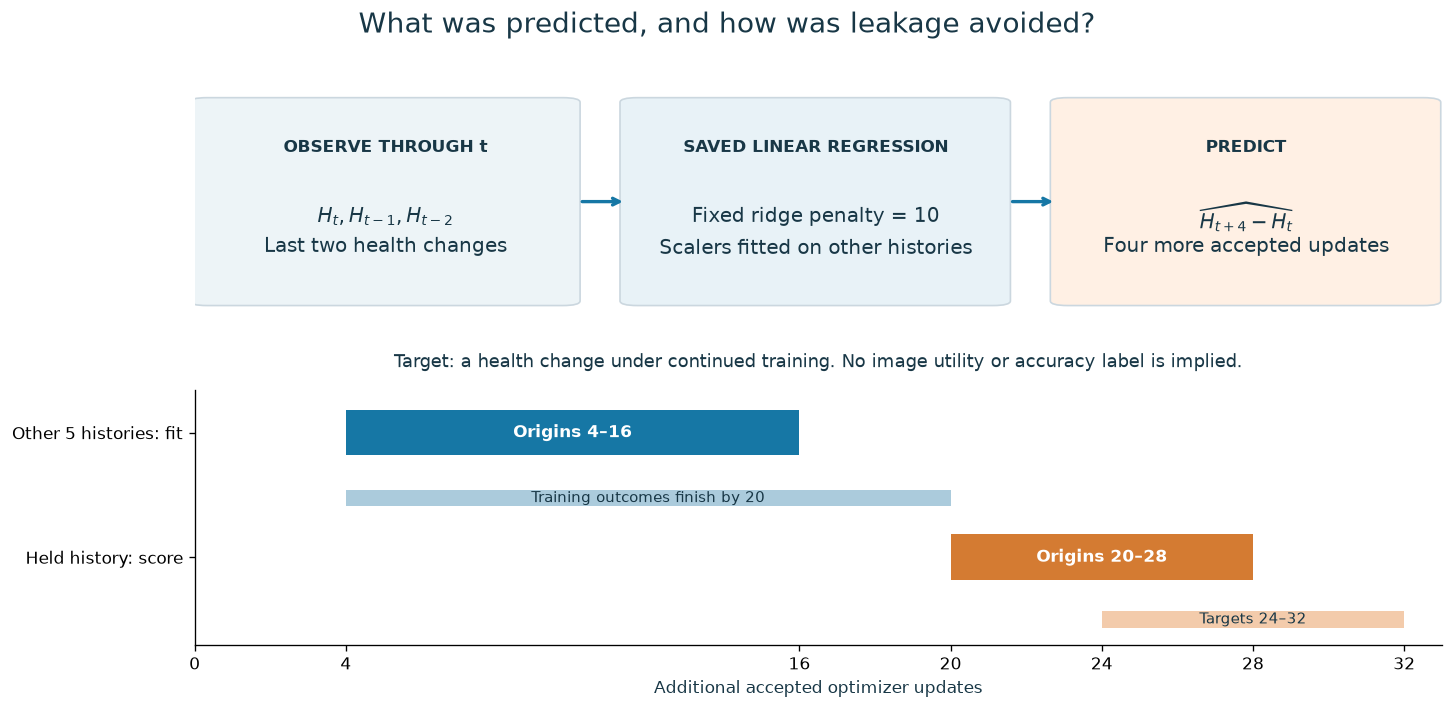

In [2]:
from pathlib import Path
from IPython.display import Image, display
root = Path.cwd()
while not (root / 'cafl4ds').is_dir() and root != root.parent:
    root = root.parent
display(Image(filename=str(root / 'outputs/research-summary/20261014-health-prediction-regressions/01-forecast-contract.png')))

In [3]:
# Reconstruct every held-history CKA forecast from saved coefficients.
result = summary["forecasts"]["4"]["cka"]
reconstructed = []
for row in result["test_rows"]:
    t = row["origin"]
    health = np.asarray(series[row["series"]]["health"])[:, 3]
    x = np.array([health[t] - health[t-1], health[t-1] - health[t-2]])
    fold = result["folds"]["delta_ar2"][row["stream"]]
    predicted_change = (fold["intercept"] +
                        ((x - fold["center"]) / fold["scale"]) @ fold["beta"])
    reconstructed.append(predicted_change)
saved = result["models"]["delta_ar2"]["predictions"]
assert np.allclose(reconstructed, saved, atol=1e-12, rtol=1e-10)
print(f"Reconstructed {len(saved)} CKA forecasts from the saved folds.")
print("Four-update MSE reduction vs persistence: "
      f"{result['models']['delta_ar2']['skill_vs_persistence_percent']:.2f}%")


Reconstructed 162 CKA forecasts from the saved folds.
Four-update MSE reduction vs persistence: 78.98%


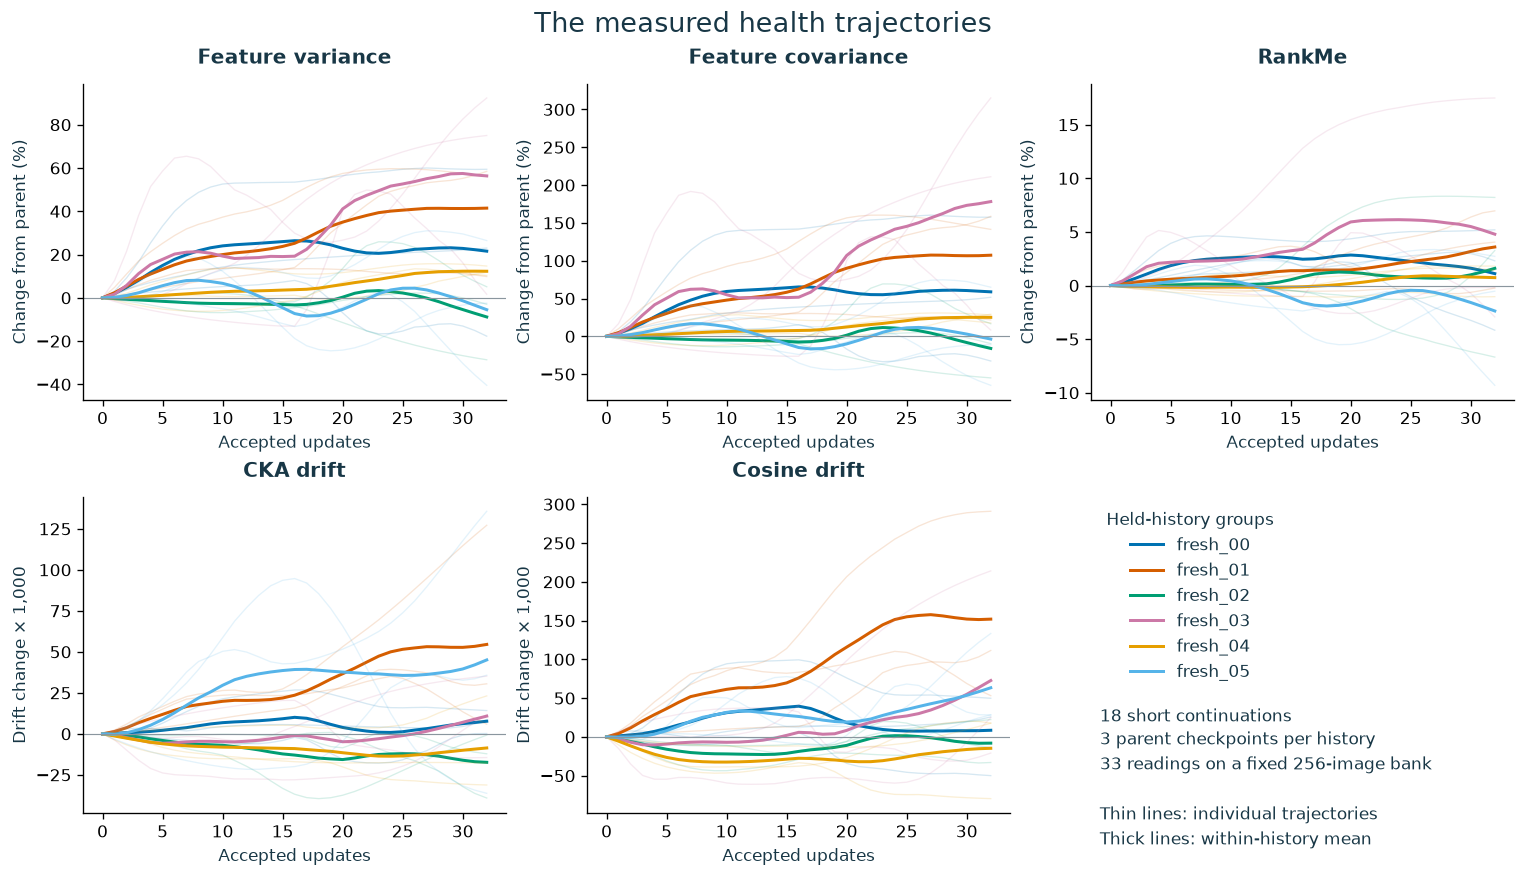

In [4]:
from pathlib import Path
from IPython.display import Image, display
root = Path.cwd()
while not (root / 'cafl4ds').is_dir() and root != root.parent:
    root = root.parent
display(Image(filename=str(root / 'outputs/research-summary/20261014-health-prediction-regressions/02-health-trajectories.png')))

## 3. Which regressions actually forecast health?

We report improvement against persistence:

$$\text{skill} = 100\left(1-\frac{\text{macro-history MSE(model)}}{\text{macro-history MSE(persistence)}}\right).$$

Positive means less squared error; negative means worse than predicting no change.
**Skill is not accuracy, probability of being right, or $R^2$ against a fitted mean.**
The calculation averages the per-history MSEs before taking their ratio.

The level-based primary AR2 passes **none** of its adjusted tests. The change model is a
strong secondary lead, particularly for RankMe and drift. It remains a secondary result;
the primary model and its ten-comparison screen were not replaced after outcomes.

| Health signal | Level AR2, four updates | Change AR2, four updates | Change AR2, one update | Histories improved at h=4 |
|---|---:|---:|---:|---:|
| Feature variance | -2.54% | 52.03% | 81.63% | 5/6 |
| Feature covariance | -2.79% | 49.91% | 83.20% | 5/6 |
| RankMe | 9.98% | 70.51% | 87.40% | 6/6 |
| CKA drift | 13.31% | 78.98% | 93.50% | 6/6 |
| Cosine drift | 7.08% | 67.59% | 91.46% | 6/6 |


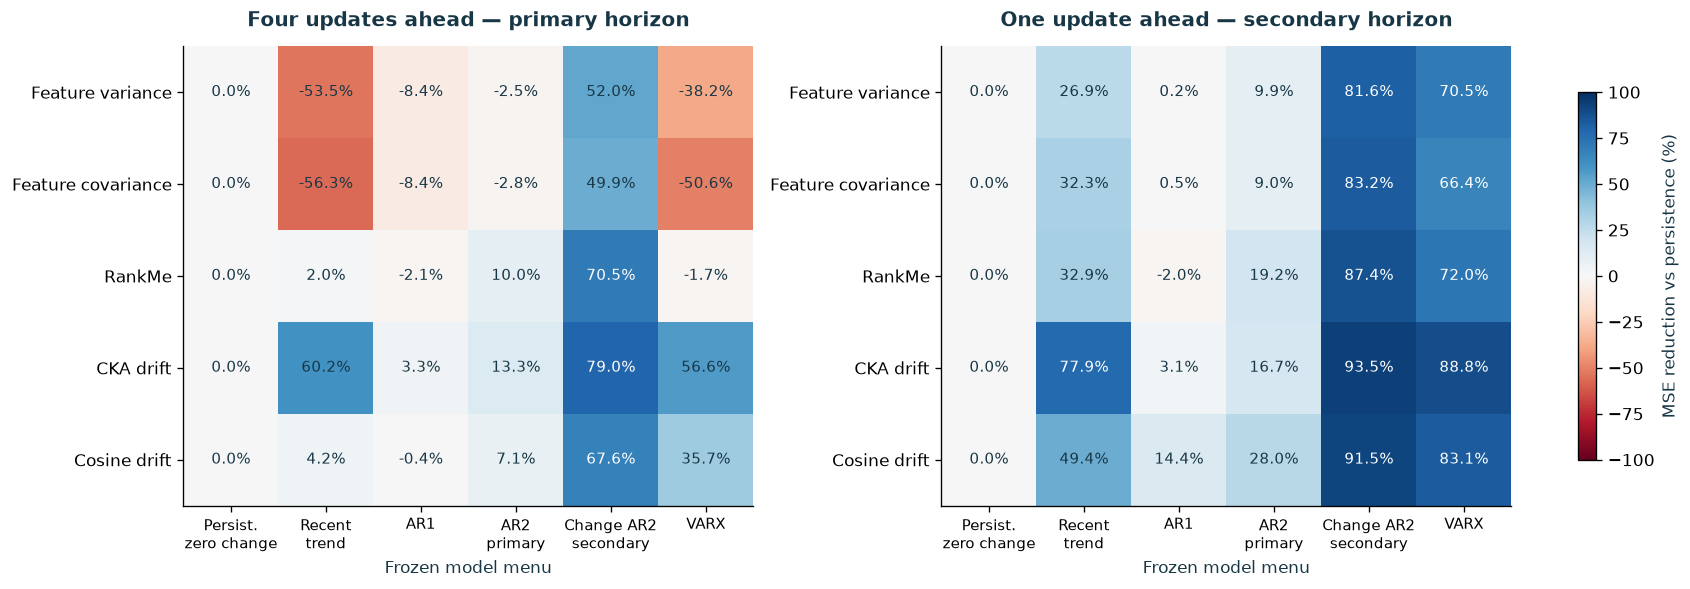

In [5]:
from pathlib import Path
from IPython.display import Image, display
root = Path.cwd()
while not (root / 'cafl4ds').is_dir() and root != root.parent:
    root = root.parent
display(Image(filename=str(root / 'outputs/research-summary/20261014-health-prediction-regressions/03-regression-scorecard.png')))

## 4. Predicted versus measured changes

These are all the saved four-update forecasts from the change model, not in-sample fits.
Each panel rescales both axes by that metric's persistence RMSE so the point clouds are comparable.
The diagonal represents a perfect prediction. Correlation alone does not establish calibration.
The original-unit errors remain visible below.

| Health signal | Persistence RMSE | Change-regression RMSE | Predicted/measured r |
|---|---:|---:|---:|
| Feature variance | 0.000474478 | 0.000328615 | 0.744 |
| Feature covariance | 0.00049554 | 0.0003507 | 0.728 |
| RankMe | 0.0603091 | 0.0327492 | 0.855 |
| CKA drift | 0.0154326 | 0.00707494 | 0.922 |
| Cosine drift | 0.0233049 | 0.0132681 | 0.803 |


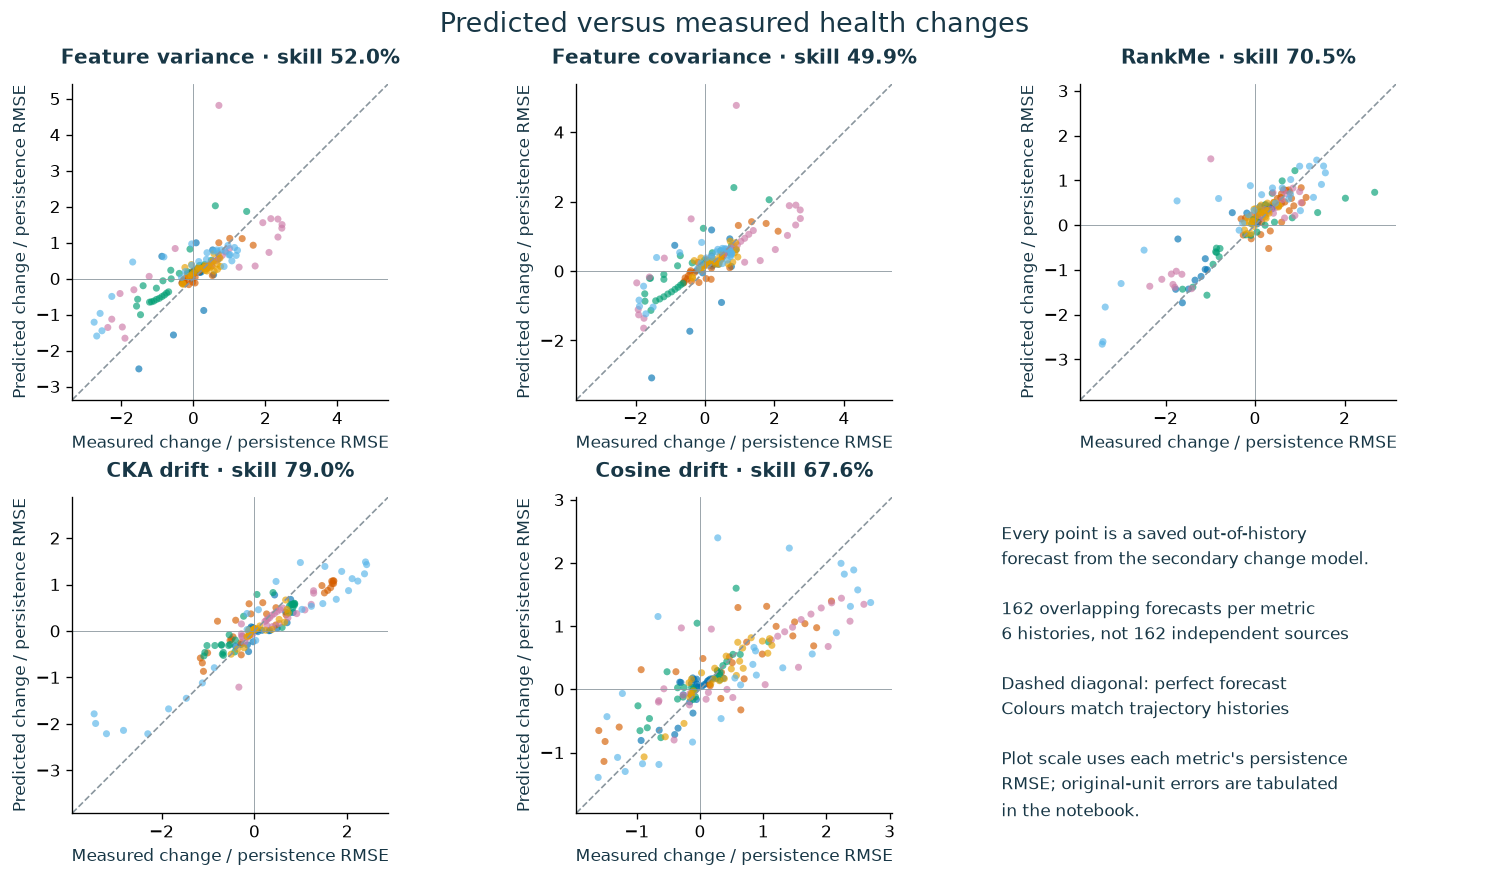

In [6]:
from pathlib import Path
from IPython.display import Image, display
root = Path.cwd()
while not (root / 'cafl4ds').is_dir() and root != root.parent:
    root = root.parent
display(Image(filename=str(root / 'outputs/research-summary/20261014-health-prediction-regressions/04-predicted-versus-measured.png')))

## 5. A concrete forecast sequence

The example is the first saved series (`fresh_00 / before_shift`), selected by index rather than fit quality.
Each prediction at target update 24–32 uses a newly observed origin four updates earlier.
The reconstructed level is $H_t+\widehat{\Delta_4H_t}$.
This is nine overlapping rolling forecasts, **not** a nine-step open-loop forecast from one state.
The all-history scatter and table carry the performance claim.


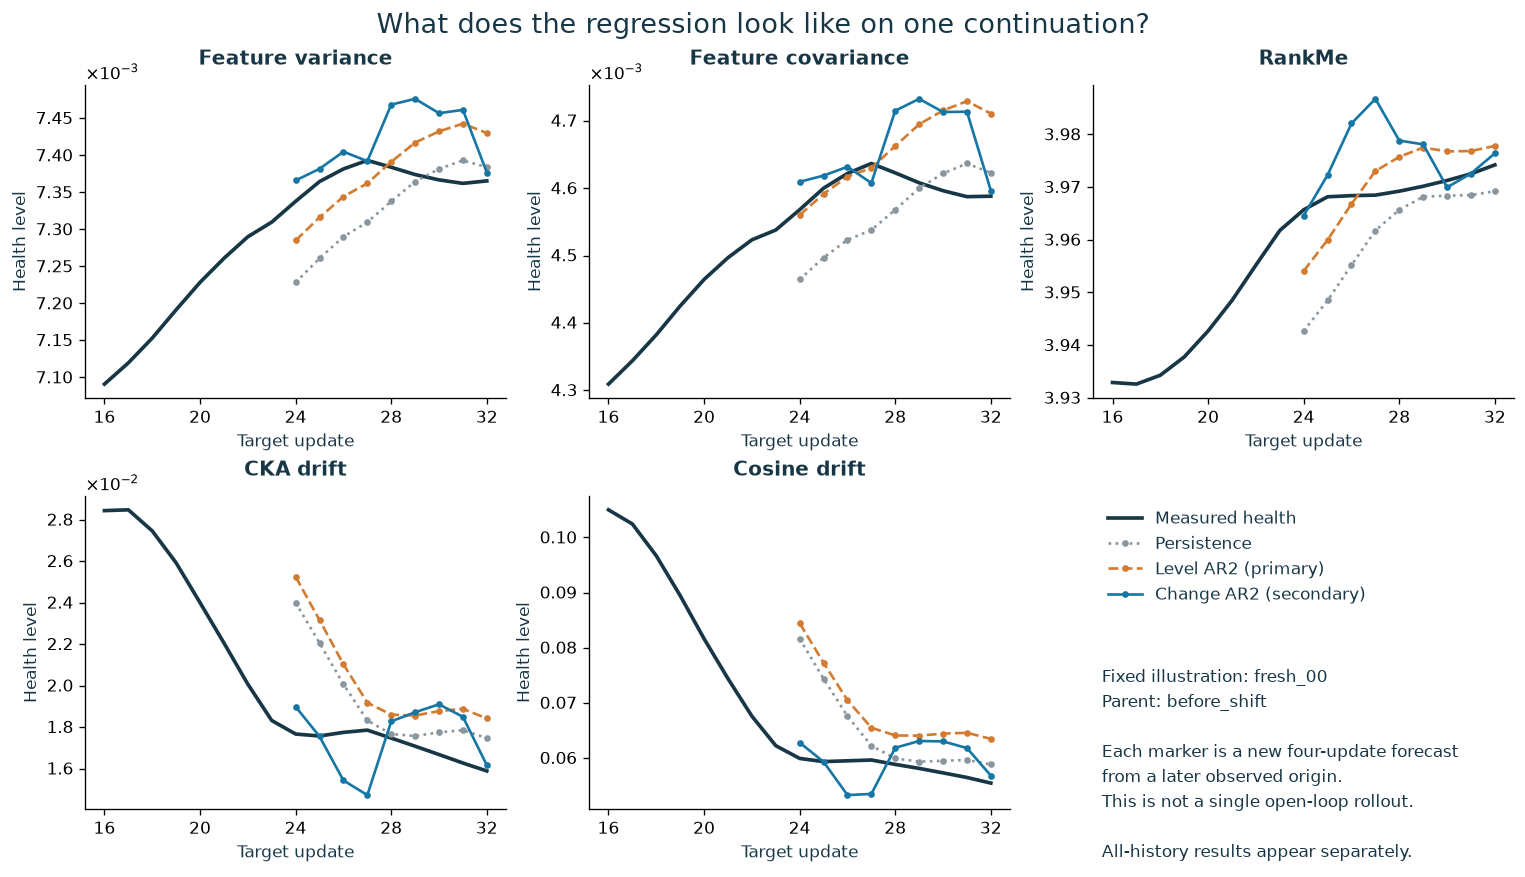

In [7]:
from pathlib import Path
from IPython.display import Image, display
root = Path.cwd()
while not (root / 'cafl4ds').is_dir() and root != root.parent:
    root = root.parent
display(Image(filename=str(root / 'outputs/research-summary/20261014-health-prediction-regressions/05-one-continuation.png')))

## 6. Does the lead hold across histories?

RankMe, CKA and cosine improve on persistence in all six histories at the four-update horizon.
Variance and covariance each have a history with negative skill. All five metrics improve in every
history at the secondary one-update horizon. These are descriptive cross-history results on reused
data, not an unused-source confirmation. No confidence interval is implied by the cell colours.


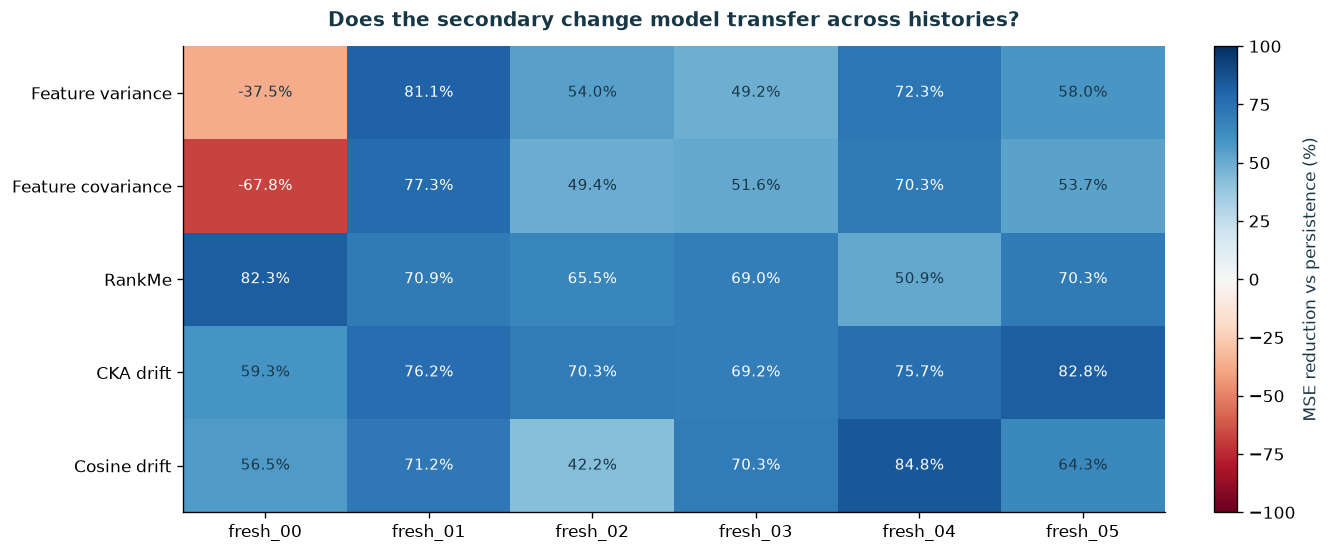

In [8]:
from pathlib import Path
from IPython.display import Image, display
root = Path.cwd()
while not (root / 'cafl4ds').is_dir() and root != root.parent:
    root = root.parent
display(Image(filename=str(root / 'outputs/research-summary/20261014-health-prediction-regressions/06-held-history-skill.png')))

## 7. Why look at autocorrelation?

The health levels are smooth. Their one-update changes also have strong positive lag-1 dependence
(roughly 0.86–0.89), which makes a regression on recent changes worth testing. High autocorrelation
alone is not a forecast evaluation: the poor level-AR2 result is a direct example.

ACF measures correlation with earlier observations at the displayed lag. Each trajectory is centered
separately; boundaries are never concatenated. Three parent trajectories are averaged within each
history before histories are averaged. Full-series detrending is a descriptive diagnostic only;
it never enters a forecast. Short series cannot establish general stationarity or seasonality.


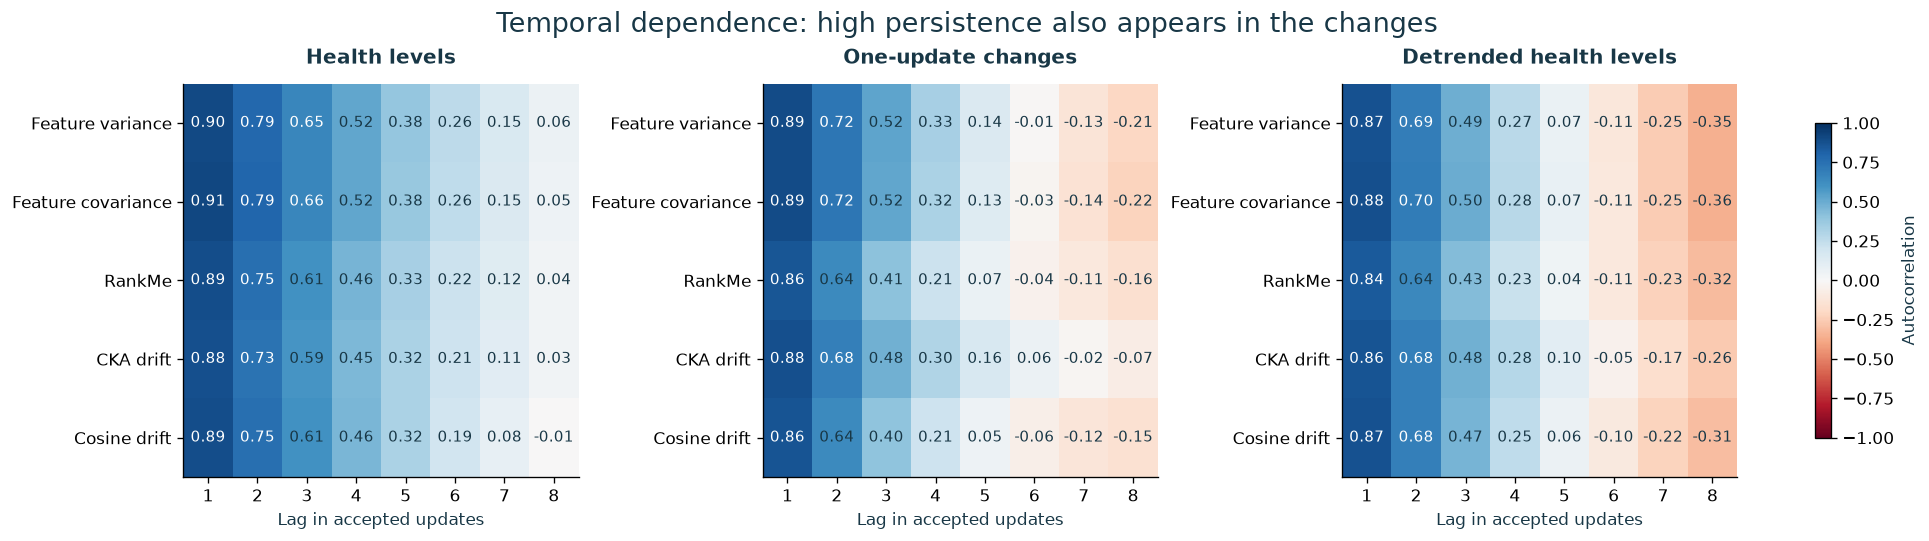

In [9]:
from pathlib import Path
from IPython.display import Image, display
root = Path.cwd()
while not (root / 'cafl4ds').is_dir() and root != root.parent:
    root = root.parent
display(Image(filename=str(root / 'outputs/research-summary/20261014-health-prediction-regressions/07-autocorrelation.png')))

### Cross-signal relationships and remaining errors

Variance/covariance increments correlate **0.987**; CKA/cosine increments correlate **0.787**
on these continuations. That suggests redundancy worth measuring, not interchangeable sensors.
The loss/norm panels use the full prespecified lag grid. Positive lag means an earlier loss or norm
precedes a later health change; zero lag is a same-update association. None establishes causation.

The forecast errors also retain temporal structure. Each residual series has only nine overlapping
test windows. The lag-1 values below are descriptive averages, with no significance or white-noise claim.

| Signal | Persistence residual lag-1 ACF | Change-model residual lag-1 ACF |
|---|---:|---:|
| Feature variance | 0.628 | 0.444 |
| Feature covariance | 0.633 | 0.455 |
| RankMe | 0.637 | 0.493 |
| CKA drift | 0.656 | 0.371 |
| Cosine drift | 0.655 | 0.404 |


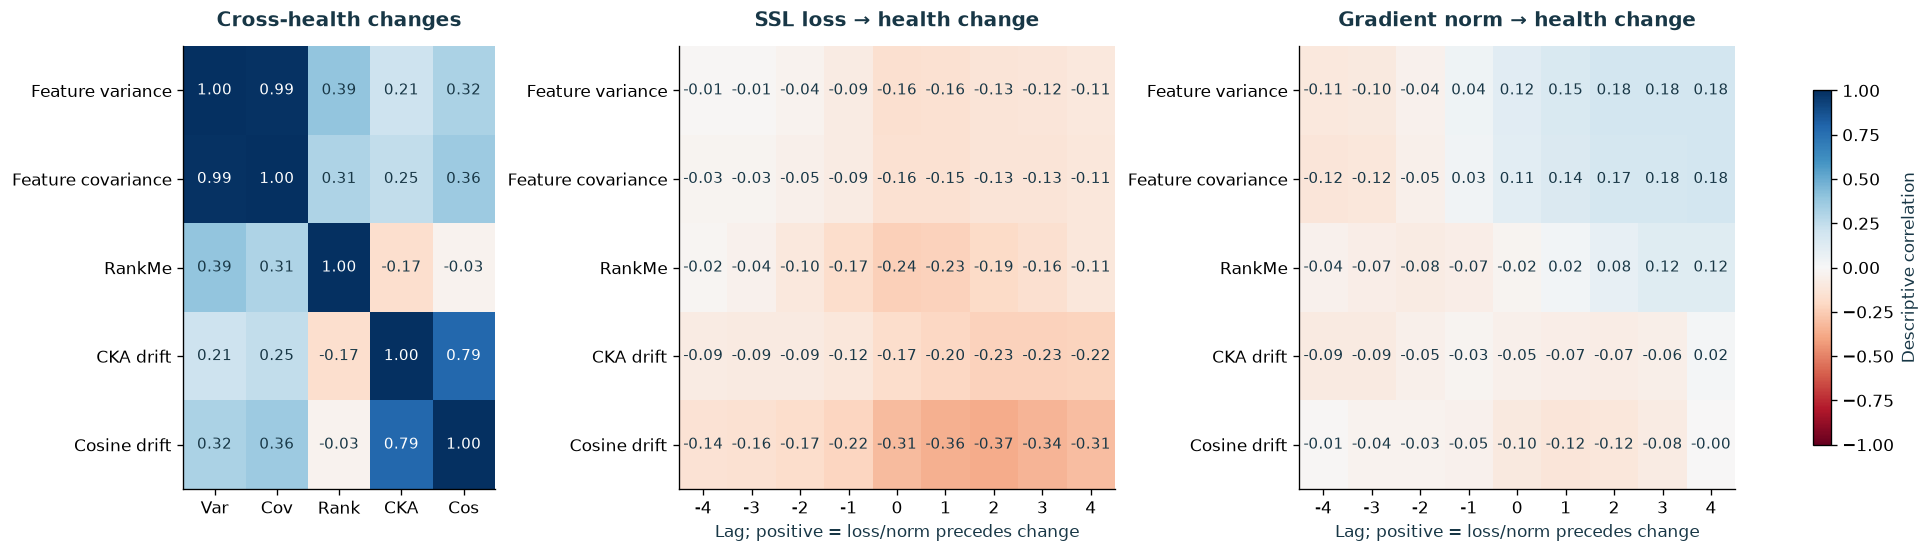

In [10]:
from pathlib import Path
from IPython.display import Image, display
root = Path.cwd()
while not (root / 'cafl4ds').is_dir() and root != root.parent:
    root = root.parent
display(Image(filename=str(root / 'outputs/research-summary/20261014-health-prediction-regressions/08-cross-correlations.png')))

## 8. What did the regression learn?

These are the saved four-update change-model coefficients converted back to original units,
with one dot per held-history fold. The latest change receives a positive weight and the previous
change a negative one. The model is sensitive to how the local rate of change is evolving.
This is a description of the fitted relation, not a causal mechanism or a universal health law.
The model also has an intercept; the figure isolates the two slope coefficients.


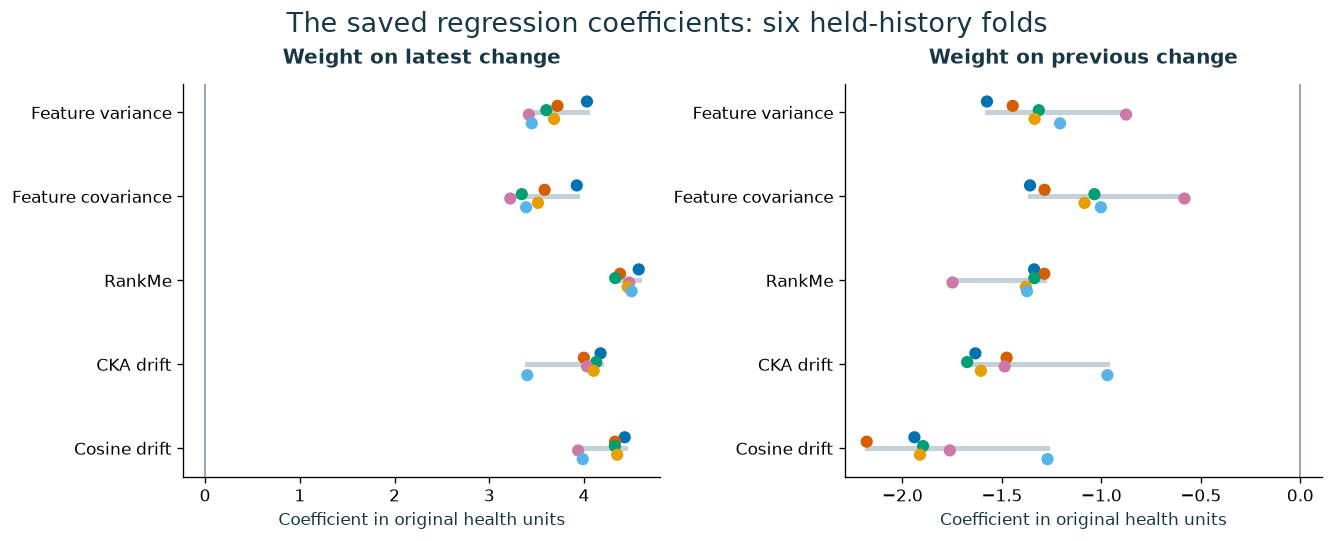

In [11]:
from pathlib import Path
from IPython.display import Image, display
root = Path.cwd()
while not (root / 'cafl4ds').is_dir() and root != root.parent:
    root = root.parent
display(Image(filename=str(root / 'outputs/research-summary/20261014-health-prediction-regressions/09-regression-coefficients.png')))

## 9. A different target: what does one image do to health?

The image experiment compared a full batch-32 update with a matched update omitting one image's
loss contribution, keeping the denominator at 32. It used **144 marginal contrasts**:
18 parents × four candidate slots × two mask/augmentation draws. This is different from forecasting
a continuation from its last health readings. The observations share parents and draws.

The cheap image/state ridge has **negative skill for all five metrics**. The paid derivative
closely approximates the saved local effects:

$$\widehat{\Delta H} = \nabla_\theta H(\theta)^\top
\left(\Delta\theta_{\mathrm{full}}-\Delta\theta_{\mathrm{omit}}\right).$$

That method requires copied AdamW updates and health gradients. It is **not a fitted regression**,
and it is not a cheap image-only prediction. Bars in this section use a zero *marginal-effect*
baseline; they must not be pooled with the time-series persistence scores.

| Marginal image effect | Cheap image/state ridge skill | Paid derivative skill |
|---|---:|---:|
| Feature variance | -27.55% | 99.82% |
| Feature covariance | -25.42% | 99.46% |
| RankMe | -93.89% | 99.71% |
| CKA drift | -25.48% | 99.43% |
| Cosine drift | -77.65% | 98.92% |

The original marginal-variance derivative passed its bounded adjusted development screen.
The four new metrics in the retrospective extension did not pass their full adjusted screen,
despite very small descriptive errors. This does not erase the signal or establish independent
generalization. Variance image effects correlate only 0.314 across the two training-view draws;
image impact depends on the state, background batch and sampled training views.


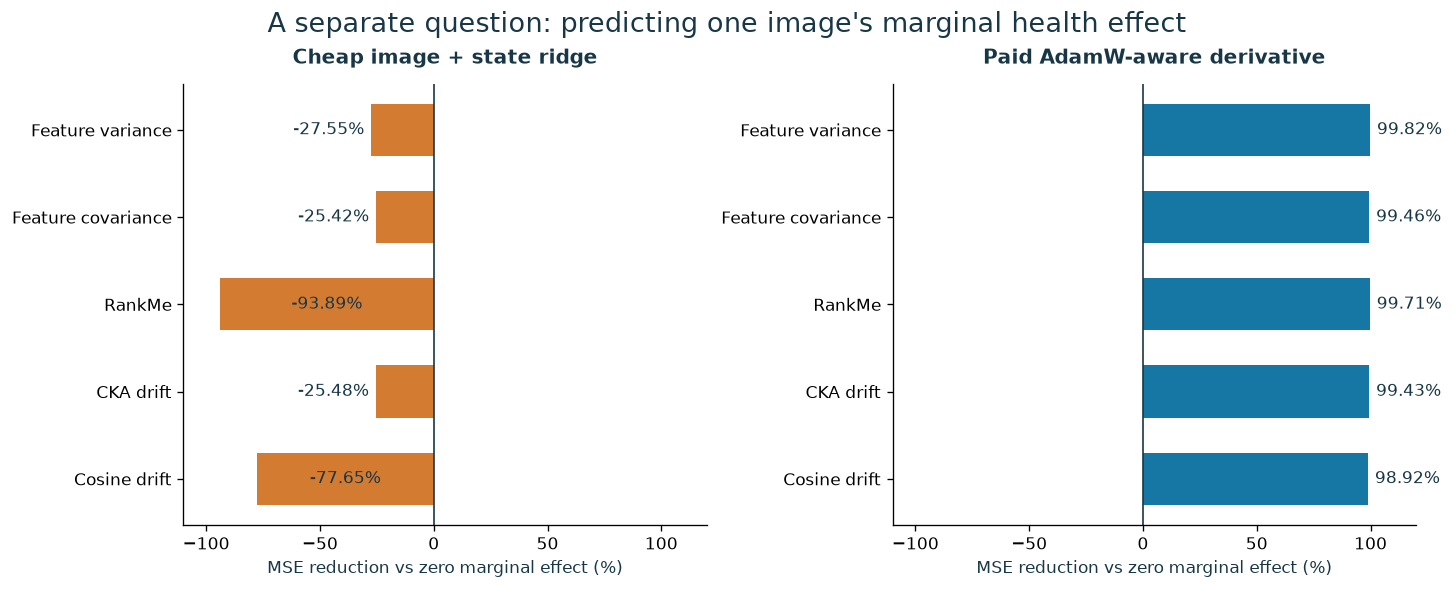

In [12]:
from pathlib import Path
from IPython.display import Image, display
root = Path.cwd()
while not (root / 'cafl4ds').is_dir() and root != root.parent:
    root = root.parent
display(Image(filename=str(root / 'outputs/research-summary/20261014-health-prediction-regressions/10-image-health-comparison.png')))

## 10. What this evidence supports

- **Short continuation forecasts:** recent-change regression is a promising secondary model for health under the same training recipe.
- **Cheap incoming-image forecasts:** the tested image/state regression did not establish calibrated marginal-effect prediction.
- **Paid local health forecasts:** optimizer-aware derivatives approximate saved one-update image effects very closely.
- **Training decisions:** none of these results calibrates which health change is good, predicts downstream accuracy reliably, or qualifies an adaptive image filter.

The histories, parent states and reference images are reused development data. Capture-session independence
is unknown, the dense time-series study uses one optimization seed, and horizons are short.
This notebook reorganizes existing evidence. It adds **zero SSL updates and zero model fits**.

Sources: `outputs/prediction-health-timeseries/20261014-pilot`,
`outputs/prediction-image-health/20261014-pilot-device-repair`, and
`outputs/prediction-health-derivatives/20261014-extension`.
The original numerical audits passed. This report also reconstructs saved targets, predictions,
training-only scalers and macro-history scores before plotting. Original result hashes are
checked against the earlier published provenance records and again after rendering.

For earlier full studies, see [time-series forecasts](05_health_timeseries.ipynb),
[metric derivatives](04_health_metric_derivatives.ipynb), and
[the original prediction pilots](03_prediction_pilots.ipynb).
Rebuild only this presentation from the repository root:
`python -m scripts.report_health_prediction_regressions`.
